In [ ]:
from gnews import GNews
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
import time

# Set start and end dates
start_date = datetime(2023, 1, 1)
end_date = datetime(2026, 11, 9)

query = '"AI bubble" OR "artificial intelligence bubble"'
daily_counts = []
current_date = start_date

print("Starting daily extraction. This will take a while...")

while current_date <= end_date:
    next_date = current_date + timedelta(days=1)
    # Query for just ONE day at a time to stay under the 100-result cap
    google_news = GNews(
        language='en',
        country='US',
        start_date=(current_date.year, current_date.month, current_date.day),
        end_date=(next_date.year, next_date.month, next_date.day),
        max_results=100
    )

    articles = google_news.get_news(query)
    count = len(articles) if articles else 0

    daily_counts.append({
        "Date": current_date,
        "Volume": count
    })

    # Print progress every 30 days
    if current_date.day == 1:
        print(f"Scraped through {current_date.strftime('%b %Y')}...")

    # Pause to prevent Google from blocking your IP
    time.sleep(3)

    # Move to the next day
    current_date += timedelta(days=1)

# Load the daily data into Pandas
df = pd.DataFrame(daily_counts)
df.set_index('Date', inplace=True)

# Resample and sum the daily counts into monthly totals
df_monthly = df.resample('ME').sum()

# Plotting the timeline
plt.figure(figsize=(12, 6))
plt.plot(df_monthly.index, df_monthly['Volume'], marker='o', linestyle='-', color='b')

plt.title('True Monthly News Volume: "AI Bubble" (Jan 2023 - Nov 2026)', fontsize=14)
plt.ylabel('Number of Articles Found', fontsize=12)
plt.xlabel('Date', fontsize=12)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

plt.show()

Starting daily headline extraction. This will take a while...
Scraped through Jan 2023...
Scraped through Feb 2023...
Scraped through Mar 2023...
Scraped through Apr 2023...
Scraped through May 2023...
Scraped through Jun 2023...
Scraped through Jul 2023...
Scraped through Aug 2023...
Scraped through Sep 2023...
Scraped through Oct 2023...
Scraped through Nov 2023...
Scraped through Dec 2023...
Scraped through Jan 2024...
Scraped through Feb 2024...
Scraped through Mar 2024...
Scraped through Apr 2024...
Scraped through May 2024...
Scraped through Jun 2024...
Scraped through Jul 2024...
Scraped through Aug 2024...
Scraped through Sep 2024...
Scraped through Oct 2024...
Scraped through Nov 2024...
Scraped through Dec 2024...
Scraped through Jan 2025...
Scraped through Feb 2025...
Scraped through Mar 2025...
Scraped through Apr 2025...
Scraped through May 2025...
Scraped through Jun 2025...
Scraped through Jul 2025...
Scraped through Aug 2025...
Scraped through Sep 2025...
Scraped throug

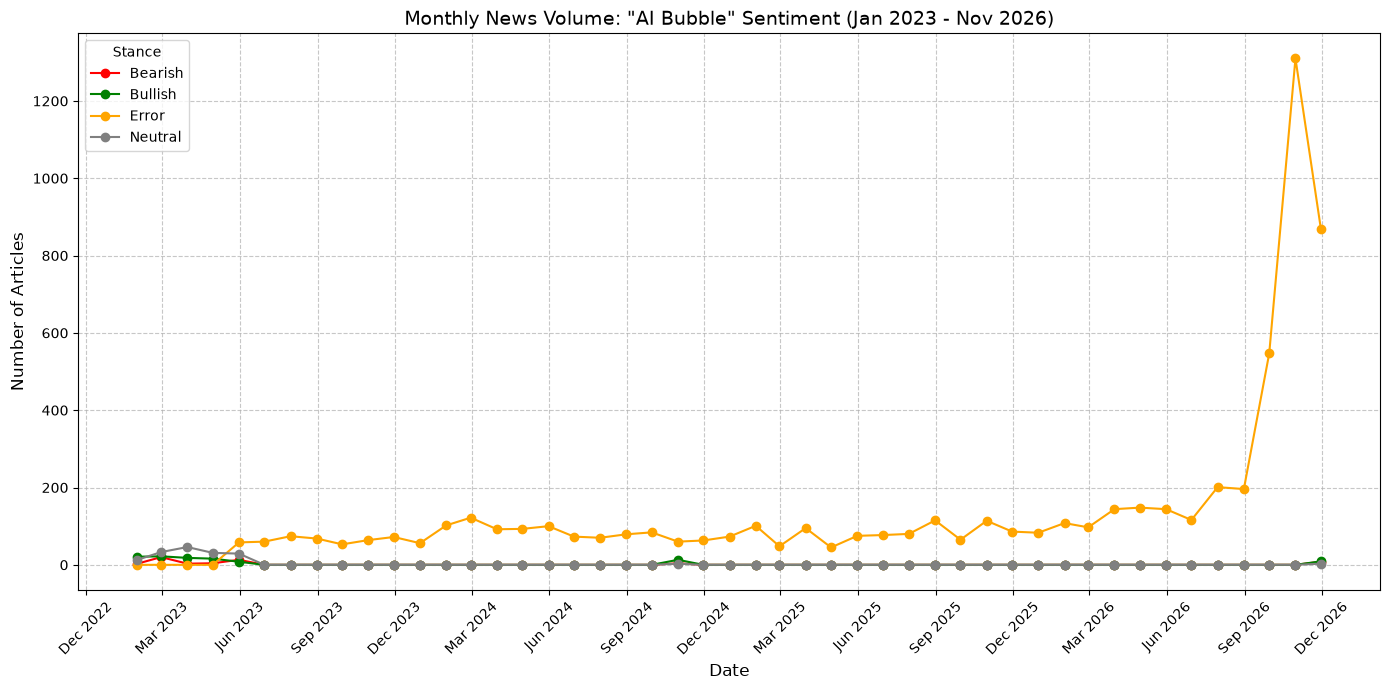

In [4]:
from gnews import GNews
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
import time
import json
import os
import getpass
from groq import Groq

# 1. Initialize Groq Client
os.environ["GROQ_API_KEY"] = getpass.getpass(prompt="Enter Groq API Key: ")

client = Groq()

def classify_headline_batch(headlines):
    prompt = f"""
    Classify the following news headlines into one of three categories regarding AI financials:
    - "Bullish" (Highlights strong earnings, revenue growth, successful funding, or surging stock prices)
    - "Bearish" (Highlights financial losses, missed earnings, plummeting stocks, or funding dry-ups)
    - "Neutral" (General financial reporting without a clear positive or negative leaning)

    Headlines:
    {json.dumps(headlines)}

    Return ONLY a valid JSON object with a single key "results".
    The value must be an array of strings representing the classifications, in the exact original order.
    """

    try:
        response = client.chat.completions.create(
            messages=[
                {"role": "system", "content": "You are a precise financial sentiment classifier. Output strictly valid JSON."},
                {"role": "user", "content": prompt}
            ],
            model="openai/gpt-oss-20b",
            response_format={"type": "json_object"},
            temperature=0.0
        )
        result_json = json.loads(response.choices[0].message.content)
        return result_json.get("results", [])
    except Exception as e:
        print(f"API Error: {e}")
        return ["Error"] * len(headlines)


# 2. Extract Headlines Daily
start_date = datetime(2023, 1, 1)
end_date = datetime(2026, 11, 9)
query = 'AI earnings OR revenue OR stock OR financials OR bubble'

all_articles = []
current_date = start_date

maxed_out_update=0
maxed_out=[]

print("Starting daily headline extraction. This will take a while...")

while current_date <= end_date:
    next_date = current_date + timedelta(days=1)

    google_news = GNews(
        language='en',
        country='US',
        start_date=(current_date.year, current_date.month, current_date.day),
        end_date=(next_date.year, next_date.month, next_date.day),
        max_results=100
    )

    articles = google_news.get_news(query)

    #if we hit a maxed out day, print it
    if(len(maxed_out) > maxed_out_update):
        print(f"number of capped days: {len(maxed_out)}")
        maxed_out_update = len(maxed_out)

    if articles and len(articles) == 100:
            maxed_out.append(current_date.strftime('%Y-%m-%d'))

    # Store the actual headlines instead of just the counts
    if articles:
        for article in articles:
            all_articles.append({
                "Date": current_date,
                "Headline": article.get("title")
            })

    if current_date.day == 1:
        print(f"Scraped through {current_date.strftime('%b %Y')}...")

    time.sleep(3) # Prevent IP block
    current_date += timedelta(days=1)

df = pd.DataFrame(all_articles)
print(f"\nExtraction complete. Found {len(df)} total articles.")


# 3. Classify Headlines via Groq
headlines_list = df["Headline"].tolist()
batch_size = 20
classifications = []

print("Starting LLM classification...")
for i in range(0, len(headlines_list), batch_size):
    batch = headlines_list[i:i + batch_size]
    if i % 100 == 0:
        print(f"Classifying batch starting at index {i}/{len(headlines_list)}...")

    results = classify_headline_batch(batch)

    # Safety catch in case the LLM returns fewer items than expected
    if len(results) != len(batch):
        results = ["Error"] * len(batch)

    classifications.extend(results)

    time.sleep(2.5) # Prevent Groq free-tier RPM block


df["Stance"] = classifications


# 4. Aggregate and Plot by Sentiment
# Set Date as index for resampling
df = df.set_index('Date')

# Group by month and stance, then unstack to create separate columns for Bubble, Not Bubble, Neutral
df_monthly = df.groupby([pd.Grouper(freq='ME'), 'Stance']).size().unstack(fill_value=0)

# Plotting
plt.figure(figsize=(14, 7))

# Define colors for clarity
colors = colors = {'Bullish': 'green', 'Bearish': 'red', 'Neutral': 'gray', 'Error': 'orange'}
available_stances = [col for col in df_monthly.columns if col in colors]

for stance in available_stances:
    plt.plot(df_monthly.index, df_monthly[stance], marker='o', linestyle='-', color=colors[stance], label=stance)

plt.title('Monthly News Volume: "AI Bubble" Sentiment (Jan 2023 - Nov 2026)', fontsize=14)
plt.ylabel('Number of Articles', fontsize=12)
plt.xlabel('Date', fontsize=12)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title='Stance')
plt.tight_layout()

plt.show()

# Optional: Save the classified raw data to CSV for later analysis
df.to_csv("classified_ai_bubble_headlines.csv")

In [5]:
print(GNews(max_results=5).get_news("Apple"))

[{'title': 'Apple’s $50 Intelligence Usage Packs extend access to some AI features - The Verge', 'description': 'Apple’s $50 Intelligence Usage Packs extend access to some AI features  The Verge', 'published date': 'Mon, 09 Nov 2026 19:09:58 GMT', 'url': 'https://news.google.com/rss/articles/CBMiqAFBVV95cUxOeEY1X0ZFY0k5R0ZvNEUzcU5qT2FYeFJhNF9WQjBZRHVrVmFUd0ZMdE45TDV6d0tRMVk0NXIzYmRYLWY5MmtvdmlFclhlTm9BQzRBQTBrUnJ1ZGtNeUtPaUkxLXZUVXVHVzV5MWxCNjAzeVp0SzFlam9lWHpYVFNwUUdBdzVJQ1RQd20teEtNTXIzNkViREVPa0lmbUpwRUVaYThBNTloN18?oc=5&hl=en-CA&gl=CA&ceid=CA:en', 'publisher': {'href': 'https://www.theverge.com', 'title': 'The Verge'}}, {'title': 'Apple CEO Presses Software Chief to Pursue More Ambitious AI Strategy - Bloomberg.com', 'description': 'Apple CEO Presses Software Chief to Pursue More Ambitious AI Strategy  Bloomberg.com', 'published date': 'Sun, 08 Nov 2026 15:00:01 GMT', 'url': 'https://news.google.com/rss/articles/CBMiyAFBVV95cUxNQjlhNk9NU1ZVZFo4UG9TR3FmcGxtMWhnY3o4R3dJNGxHc3E2QlR4cm

In [9]:
google_news = GNews(
    language='en',
    country='US',
    start_date=(current_date.year, current_date.month, current_date.day),
    end_date=(next_date.year, next_date.month, next_date.day),
    max_results=100
)

query = 'AI earnings OR revenue OR stock OR financials OR bubble'
print(
    GNews(max_results=5,
            start_date=datetime(2023, 6, 1),
            end_date=datetime(2023, 6, 10)
            ).get_news(query)
)

[{'title': "20 Artificial Intelligence Stock Picks, and 10 AI Predictions, From RBC - Barron's", 'description': "20 Artificial Intelligence Stock Picks, and 10 AI Predictions, From RBC  Barron's", 'published date': 'Fri, 09 Jun 2023 07:00:00 GMT', 'url': 'https://news.google.com/rss/articles/CBMilwFBVV95cUxNYzVNVmFKTXFhLVUtenhpcnlvVXFBeWNKSVMwdFl4MEl0b2NCeURZOURiSzI5SEtjc3VGVkhGNlZDVUhZX05YekF2dXpZaHJiQm53czhYTlpITW5kQ2pDLUI0UDdCSHNuc0hFeGFjbTJfM3VQcmFQbHFRQnNaZ3pkTkJMQmxzYl9IRXp4UEEyNHNhMnpOUndV?oc=5&hl=en-CA&gl=CA&ceid=CA:en', 'publisher': {'href': 'https://www.barrons.com', 'title': "Barron's"}}, {'title': 'Generative AI to Become a $1.3 Trillion Market by 2032, Research Finds - Bloomberg.com', 'description': 'Generative AI to Become a $1.3 Trillion Market by 2032, Research Finds  Bloomberg.com', 'published date': 'Thu, 01 Jun 2023 07:00:00 GMT', 'url': 'https://news.google.com/rss/articles/CBMirgFBVV95cUxOQkhGTFlVX0pUS200YlJXQWVHOVREUHZoWlo2T0NYY0RKUmhHVkpreE9ZNXoxbWNxc21keGZfU0o2W